# Lab 08 · Indexing with Graphs
## Student edition

Semantic vectors, exact nearest neighbours, HNSW, and reliable evaluation.

This edition contains the full conceptual explanations and worked numerical examples. Complete the marked implementation gaps, run the checks, and record your observations. These notes also serve as a revision guide.

The core sequence follows the supplied lab: prepare embeddings → construct indices → build a query bucket and exact references → compute recall → test HNSW → compare parameters → plot and interpret results. Additional background and corrections are explicitly identified. The implementation still uses **NMSLIB**, not a replacement vector-search library.

Read the explanations before each implementation. Run cells in order. A cell that raises `NotImplementedError` is an exercise, not an installation failure. Complete it before running dependent cells. Installation and dataset/model downloads require internet access; the numerical warm-up needs only NumPy.

### Reading route

Start with the retrieval problem and the numerical example. Then study Sections 0 and 1 before running the main experiment. Sections 2 and 3 explain how to evaluate and tune the index. The final revision guide links the definitions, equations, and common mistakes.


### Expanded HNSW visual walkthrough

Section 1 now includes the complete algorithm-and-library explanation, embedded hierarchy and search diagrams, the random-level formula, a hand-traced search, a runnable Python demonstration, construction and neighbour-diversity reasoning, parameter interpretation, and the NMSLIB lifecycle. The figures are embedded in the notebook; there are no image-file dependencies. The same core explanations appear in both editions.

For a focused review, jump to [HNSW and NMSLIB](#hnsw-and-nmslib), [layers](#hnsw-layers), [the worked search](#hnsw-trace), or [construction](#hnsw-construction). The small teaching demonstration can be run independently. Main lab experiments still require the dataset, model, and NMSLIB environment.


## The problem we are solving

A question such as “How do stars produce energy?” should ideally retrieve related questions even when they do not contain exactly the same words. We first encode each question as a vector. We then search for nearby vectors. An **embedding model** defines the representation; an **index** organises the stored vectors so that retrieval can be efficient.

The source lab indexes the Jeopardy CSV's `Question` field. The `Answer` field is metadata that we can display with a retrieved question; it is not a training target or a vector in this lab. We do not train a neural network, generate an answer, or construct a graph of web hyperlinks.

An inverted index maps terms to documents. The graph index in this lab connects vector IDs to other vector IDs. An edge is a navigation link, not an assertion that the two questions have a factual relationship.

### End-to-end steps

```text
OFFLINE / PREPARATION
CSV records → clean Question text → embed every question → vector matrix
                                                  ├→ exact search reference
                                                  └→ HNSW graph index

ONLINE / QUERYING
query text → same cleaning and embedding → query vector → search index
          → ranked vector IDs + distances → look up original records

EVALUATION
same corpus + same query + same distance
          → compare HNSW IDs with exact IDs → recall and measured time
```

A new query is normally **not inserted** into the index. Its vector is compared with stored vectors during search.

### Symbols used throughout

| Symbol | Meaning |
|:--|:--|
| $D$ | Number of indexed questions in the current experiment |
| $d$ | Number of coordinates in one embedding |
| $Q$ | Number of evaluation queries |
| $k$ | Number of neighbours requested from the index |
| $N$ | Evaluation cutoff used by `recall@N`; often equal to $k$ |
| $X$ | Matrix with shape $(D,d)$; row $i$ is vector $x_i$ |
| $q$ | One query vector, with shape $(d,)$ |

Do not confuse dataset size $D$, embedding dimension $d$, graph degree control `M`, and requested result count $k$.


## A numerical warm-up: similarity before indexing

For nonzero vectors, cosine similarity is the normalised dot product:

$$s(q,x)=\frac{q^T x}{\|q\|_2\|x\|_2}.$$

The dot product is $q^T x=\sum_{j=1}^{d}q_jx_j$, and the Euclidean norm is $\|x\|_2=\sqrt{\sum_{j=1}^{d}x_j^2}$.

NMSLIB's space called `cosinesimil` returns **cosine distance**, not similarity [R3]:

$$\delta(q,x)=1-s(q,x).$$

A smaller distance means a closer neighbour. Cosine similarity lies in $[-1,1]$ and cosine distance in $[0,2]$, apart from floating-point rounding. The distance is zero for vectors pointing in the same direction, one for orthogonal vectors, and two for opposite directions. Zero vectors are invalid for this formula because the denominator would be zero.

Take $q=(1,0)$ and four stored vectors:

| ID | Vector | Cosine similarity | Cosine distance |
|:--|:--|--:|--:|
| 0 | $(1,0)$ | 1 | 0 |
| 1 | $(0.8,0.6)$ | 0.8 | 0.2 |
| 2 | $(0,1)$ | 0 | 1 |
| 3 | $(-1,0)$ | -1 | 2 |

For ID 1, the dot product is $1(0.8)+0(0.6)=0.8$, both norms are one, and the distance is $1-0.8=0.2$. The exact nearest two IDs are therefore `[0, 1]`. These vectors are an invented mathematical example, not measured text embeddings.

Scaling a vector by a **positive** constant does not change its cosine similarity. For unit-normalised vectors, the following identity explains why squared Euclidean and cosine rankings agree:

$$\|\hat q-\hat x\|_2^2=2-2\hat q^T\hat x=2\delta(q,x).$$

We will keep `cosinesimil` explicitly; normalisation is not permission to switch metrics inconsistently.


In [ ]:
import numpy as np

EPS = 1e-12
TOY_VECTORS = np.array([[1, 0], [0.8, 0.6], [0, 1], [-1, 0]], dtype=np.float32)
TOY_QUERY = np.array([1, 0], dtype=np.float32)


### Implementation A · Compute one cosine distance

**Input:** two one-dimensional, equally sized, nonzero numeric vectors. **Output:** one floating-point distance.

**Steps.** Convert both inputs to arrays. Check their shapes and finite values. Compute both norms. Reject a zero norm. Divide the dot product by the product of the norms. Clip numerical rounding to $[-1,1]$. Return one minus the similarity.

**Hint.** `np.dot`, `np.linalg.norm`, and `np.clip` correspond directly to the formula. The validation is provided; implement the final arithmetic.


In [ ]:
def cosine_distance(q, x):
    q = np.asarray(q, dtype=np.float64)
    x = np.asarray(x, dtype=np.float64)
    if q.ndim != 1 or x.shape != q.shape or q.size == 0:
        raise ValueError("Expected nonempty vectors of the same one-dimensional shape.")
    if not np.isfinite(q).all() or not np.isfinite(x).all():
        raise ValueError("Vectors must contain only finite numbers.")
    denominator = np.linalg.norm(q) * np.linalg.norm(x)
    if denominator <= EPS:
        raise ValueError("Cosine distance is undefined for a zero vector.")
    # TODO: compute the similarity, clip rounding, and return the distance.
    raise NotImplementedError("Implement cosine_distance.")


In [ ]:
toy_distances = np.array([cosine_distance(TOY_QUERY, x) for x in TOY_VECTORS])
assert np.allclose(toy_distances, [0, 0.2, 1, 2], atol=1e-7)
assert np.isclose(cosine_distance([1, 0], [8, 6]), 0.2)
print("Distances:", toy_distances.round(3))
print("Exact top-2 IDs:", np.argsort(toy_distances)[:2].tolist())


## 0 · Environment and embedding prerequisites

The original lab uses spaCy and offers fastText as an alternative. Both remain available here, but choose **one** backend for an entire run. They are different models and their coordinate systems are not interchangeable, even if their output dimensions match.

Run the following in a terminal, or use `%pip` in a notebook for the package installation. Use the Python interpreter associated with the notebook kernel when downloading the model:

```bash
python -m pip install numpy pandas matplotlib tqdm spacy nmslib
python -m spacy download en_core_web_md
```

Then restart the notebook kernel. Do not uninstall a working NMSLIB installation automatically. A source build may require a compiler and Python development headers; it is a platform-specific troubleshooting step, not a universal requirement [R1]. The source notebook's old M1/Python-3.8 warning is not treated as a current compatibility guarantee.

For the optional fastText backend, install `fasttext` and obtain its English model separately. Select that backend in the configuration, set `FASTTEXT_MODEL`, and rebuild all vectors and references. The large pretrained model is not included in this handout.

### What an embedding means

An embedding is a function $f$ that maps text into a fixed-length numeric vector:

$$f:\mathrm{text}\rightarrow\mathbb{R}^{d},\qquad x_i=f(t_i),\qquad q=f(t_q).$$

For the default spaCy document vector used here, the representation is an average of token vectors [R4]:

$$f(t)=\frac{1}{L}\sum_{j=1}^{L}e(w_j).$$

Here $L$ is the number of tokens and $e(w_j)$ is the pretrained vector for token $j$. The actual dimension is read from the loaded model rather than hard-coded. A coordinate is a learned feature, not a named Jeopardy category. Averaging is a simple baseline: it loses much information about word order and does not guarantee good question-level semantic matching.

No model is trained on Jeopardy in this lab. Loading pretrained vectors and building a search index are different operations. `nlp.make_doc(text)` tokenises with the model's vocabulary without running unnecessary tagging, parsing, or entity-recognition components [R5]. For this static-vector baseline, those components are not needed.

**Correction to the source.** The supplied spaCy `embed(text)` reads a global `line['Question']` instead of `text`. It can raise `NameError` or reuse the last CSV record. Here, the function must use its own argument. The alternative fastText definition in the source happens to overwrite the broken spaCy function when both cells are run; relying on execution order is not a repair.


In [ ]:
from pathlib import Path
import csv
import gc
import hashlib
import html
import io
import json
import platform
import re
import shutil
import sys
import time
import urllib.request
import zipfile
from importlib import metadata
from itertools import product

import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

MODE = "classroom"  # Change to "original_scale" for the source lab's full grid.
PROFILES = {
    "classroom": dict(max_records=5000, ds=[2000, 5000], ms=[8, 16],
                      efs=[100, 200, 400], max_sample_queries=100),
    "original_scale": dict(max_records=30000,
                           ds=[2000, 5000, 10000, 20000, 30000],
                           ms=[8, 16, 32, 64], efs=[100, 200, 400],
                           max_sample_queries=None),
}
CFG = PROFILES[MODE]
DATASET_PATH = Path("JEOPARDY_CSV.csv")
DOWNLOAD_IF_MISSING = True
EMBED_BACKEND = "spacy"  # or "fasttext"
SPACY_MODEL = "en_core_web_md"
FASTTEXT_MODEL = Path("cc.en.300.bin")
CACHE_DIR = Path("graph_lab_cache")
RESULTS_DIR = Path("graph_lab_results")
NUM_THREADS = 1
BUILD_THREADS = 1
REPEATS = 3
POST = 2  # Retain the source lab's postprocessing choice; keep it fixed.
K_SMALL, K_LARGE = 100, 1000

for folder in (CACHE_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Profile:", MODE, "| maximum records:", CFG["max_records"])
print("Python:", platform.python_version(), "| executable:", sys.executable)


The classroom profile reduces dataset and query counts, not the concepts. It keeps both top-100 and top-1000 retrieval. The original-scale profile restores the five dataset sizes, four `M` settings, and three `ef` settings from the source: 60 paired configurations. HNSW graph construction can vary across runs; a NumPy random seed alone does not guarantee identical NMSLIB graphs. Thread counts are explicit and recorded.


In [ ]:
if EMBED_BACKEND == "spacy":
    import spacy
    try:
        nlp = spacy.load(SPACY_MODEL)
    except OSError as exc:
        raise RuntimeError(
            f"Install the model in this kernel's environment: "
            f"{sys.executable} -m spacy download {SPACY_MODEL}"
        ) from exc
    if nlp.vocab.vectors_length == 0:
        raise ValueError("This model has no static word vectors. Use a vector-enabled model.")
    MODEL_ID = f"spacy:{spacy.__version__}:{nlp.meta['name']}:{nlp.meta['version']}"
elif EMBED_BACKEND == "fasttext":
    import fasttext
    if not FASTTEXT_MODEL.is_file():
        raise FileNotFoundError(f"Place the pretrained model at {FASTTEXT_MODEL.resolve()}.")
    ft = fasttext.load_model(str(FASTTEXT_MODEL))
    stat = FASTTEXT_MODEL.stat()
    MODEL_ID = f"fasttext:{FASTTEXT_MODEL.resolve()}:{stat.st_size}:{stat.st_mtime_ns}"
else:
    raise ValueError("Choose 'spacy' or 'fasttext'.")
print("Embedding identity:", MODEL_ID)


### Implementation B · Embed the supplied text

**Input:** one text string. **Output:** a one-dimensional `float32` vector.

**Steps.** Use the selected backend. For spaCy, obtain a document from the function argument and read its vector. For fastText, call `ft.get_sentence_vector(text)`. Convert the result to a NumPy `float32` array.

**Hint.** Do not refer to a global CSV row. Normalisation and zero-vector handling are checked separately. The same function will embed both dataset questions and topic queries.


In [ ]:
def embed(text: str) -> np.ndarray:
    if not isinstance(text, str):
        raise TypeError("embed expects a text string.")
    # TODO: call the selected backend using text, then return a float32 array.
    raise NotImplementedError("Implement embed without using a global CSV row.")


In [ ]:
probe_a, probe_b = embed("cats"), embed("quantum physics")
assert probe_a.ndim == 1 and probe_a.shape == probe_b.shape
assert probe_a.size > 0 and np.isfinite(probe_a).all()
assert np.linalg.norm(probe_a) > EPS and np.linalg.norm(probe_b) > EPS
assert not np.allclose(probe_a, probe_b), "Different probes unexpectedly have identical vectors."
print("Embedding dimension:", probe_a.size)


## Generate the vector dataset

A search result contains a numeric ID, not the question text. We therefore need a permanent alignment:

$$\mathrm{ID}=i\quad\longleftrightarrow\quad X[i]\quad\longleftrightarrow\quad\mathrm{records}[i].$$

The source notebook calls the list of row dictionaries `strings`. Here it is named `records` to make its contents clearer. `source_row` records the original CSV row index, while the search ID is the position **after** filtering.

### Load and clean the questions

The provided loader locates the CSV, optionally downloads the source lab's archive, strips whitespace from column names, decodes HTML entities, removes HTML tags, and normalises whitespace. Empty questions are skipped. Duplicate questions are retained to stay close to the source; the evaluation discussion explains the resulting ties.

**Steps.** Locate the file → normalise headers → clean each `Question` → keep its metadata and original row ID → stop at the configured limit. This is preprocessing added to the supplied lab; applying it consistently matters more than the particular choice of cleaning rules.


In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/hsu-ai-course/hsu.ai/master/"
    "code/datasets/nlp/JEOPARDY_CSV.zip"
)
CLEANING_VERSION = "html-tags-entities-whitespace-v1"

def clean_text(text: str) -> str:
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]*>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def ensure_dataset(path: Path, download: bool) -> Path:
    if path.is_file():
        return path
    if not download:
        raise FileNotFoundError(f"Place JEOPARDY_CSV.csv at {path.resolve()}.")
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "IR-Graph-Lab/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=45) as response:
            payload = response.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            candidates = [n for n in archive.namelist()
                          if n.lower().endswith(".csv") and not n.startswith("__MACOSX/")]
            if len(candidates) != 1:
                raise ValueError(f"Expected one CSV in the archive, found {candidates}.")
            path.parent.mkdir(parents=True, exist_ok=True)
            # Copy only the CSV bytes; do not extract arbitrary archive paths.
            with archive.open(candidates[0]) as source, path.open("wb") as target:
                shutil.copyfileobj(source, target)
    except Exception as exc:
        raise RuntimeError(
            "Dataset download failed. Download the archive from the source lab "
            "and place its CSV at DATASET_PATH."
        ) from exc
    return path

def load_records(path: Path, limit: int) -> list:
    if limit < 1:
        raise ValueError("limit must be positive.")
    rows = []
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames is None:
            raise ValueError("The CSV has no header.")
        reader.fieldnames = [name.strip() for name in reader.fieldnames]
        if "Question" not in reader.fieldnames:
            raise ValueError(f"No Question column; found {reader.fieldnames}.")
        for source_row, row in enumerate(reader):
            question = clean_text(row.get("Question") or "")
            if not question:
                continue
            record = {str(k).strip(): v for k, v in row.items() if k is not None}
            record.update(Question=question, source_row=source_row)
            rows.append(record)
            if len(rows) == limit:
                break
    if not rows:
        raise ValueError("No usable questions were loaded.")
    return rows

records = load_records(ensure_dataset(DATASET_PATH, DOWNLOAD_IF_MISSING), CFG["max_records"])
print("Loaded records:", len(records))
display(pd.DataFrame(records[:3]))


### Build vectors and reuse them safely

Embedding a corpus can be more expensive than one search. A cache avoids recomputing unchanged embeddings. A valid cache must belong to the **same cleaned texts, in the same order, and the same embedding model**. A file named simply `vectors` is not enough evidence.

The helper below fingerprints those inputs and stores numeric arrays in `.npz`, without pickle. It validates shape when loading. Afterward, it removes invalid or zero-vector rows from both the matrix and records together. The fastText identity uses local file metadata; replace/delete the cache after modifying a model while preserving its file metadata.

The matrix is sized from the records actually loaded, not from the requested maximum. For 30,000 rows, 300 dimensions, and four-byte `float32` numbers, the raw matrix alone requires:

$$30000\times300\times4=36000000\ \mathrm{bytes}.$$

That is 36 MB in decimal units, before graph links, text records, model weights, or temporary buffers. `M` does not change this matrix's shape; it affects the graph built over it.


In [ ]:
def embedding_matrix(rows: list, embed_fn, model_id: str, cache_dir: Path):
    texts = [r["Question"] for r in rows]
    identity = json.dumps({"texts": texts, "model": model_id,
                           "cleaning": CLEANING_VERSION}, ensure_ascii=False)
    digest = hashlib.sha256(identity.encode("utf-8")).hexdigest()
    path = cache_dir / f"vectors_{digest[:20]}.npz"
    if path.is_file():
        with np.load(path, allow_pickle=False) as saved:
            if saved["fingerprint"].item() != digest:
                raise ValueError("Cache identity mismatch.")
            matrix = saved["vectors"].astype(np.float32, copy=False)
        print("Loaded vector cache:", path.name)
    else:
        matrix = np.vstack([embed_fn(t) for t in tqdm(texts, desc="Embedding questions")])
        matrix = np.asarray(matrix, dtype=np.float32)
        np.savez_compressed(path, vectors=matrix, fingerprint=np.array(digest))
        print("Saved vector cache:", path.name)
    if matrix.ndim != 2 or matrix.shape[0] != len(rows) or matrix.shape[1] == 0:
        raise ValueError("The vector matrix is not aligned with the loaded records.")
    return matrix, digest

vectors, EMBEDDING_FINGERPRINT = embedding_matrix(records, embed, MODEL_ID, CACHE_DIR)
valid = np.isfinite(vectors).all(axis=1) & (np.linalg.norm(vectors, axis=1) > EPS)
removed = int((~valid).sum())
records = [record for record, keep in zip(records, valid) if keep]
vectors = np.ascontiguousarray(vectors[valid], dtype=np.float32)
if len(records) < K_LARGE:
    raise ValueError("At least 1000 valid questions are needed for this lab's large-k experiment.")
DS = [D for D in CFG["ds"] if D <= len(records)]
if not DS or DS[-1] != len(records):
    DS.append(len(records))
DS = sorted(set(DS))
MS, EFS = CFG["ms"], CFG["efs"]
assert vectors.shape[0] == len(records)
assert vectors.shape[1] == probe_a.size, "Cache/model dimension mismatch."
print("Removed invalid vectors:", removed)
print("Matrix:", vectors.shape, "| dtype:", vectors.dtype)
print("Raw vector memory (MB):", round(vectors.nbytes / 1_000_000, 2))
print("Dataset sizes actually tested:", DS)


<a id="index-construction"></a>
## 1 · Index construction

### Exact search: our reference, not an answer key for meaning

For a query $q$, exact search evaluates the distance to every indexed vector and selects the $k$ IDs with the smallest values:

$$G_k(q;D)=\operatorname{TopKSmallest}_{i\in\{0,\ldots,D-1\}}\delta(q,x_i).$$

Computing all distances takes $O(Dd)$ coordinate-level work. For 30,000 vectors with 300 coordinates, the dot products alone involve $30{,}000\times300=9{,}000{,}000$ coordinate products per query. A full sort would add $O(D\log D)$ work, but top-$k$ selection need not fully sort the collection. NMSLIB names its exhaustive method `brute_force` [R2].

Here, **ground truth means exact neighbours under the selected embedding and distance**. It does not mean human-labelled relevant questions. An approximate search can match the exact vector ranking perfectly while the retrieved questions are semantically disappointing.

The walkthrough below expands the graph-search background discussed in the companion explanation. Its small graphs, node heights, and distances are constructed teaching examples, not measurements or an extracted graph from the Jeopardy corpus. The original lab's NMSLIB implementation and experiments continue after the walkthrough.

**Reading map:** [algorithm versus library](#hnsw-and-nmslib) → [graph layers](#hnsw-layers) → [query search](#hnsw-search) → [worked trace](#hnsw-trace) → [construction](#hnsw-construction) → [parameters](#hnsw-parameters) → [NMSLIB calls](#nmslib-lifecycle).

<a id="hnsw-and-nmslib"></a>
### HNSW and NMSLIB have different responsibilities

**HNSW** means **Hierarchical Navigable Small World**. It is an algorithm and a graph-based data structure for approximate nearest-neighbour search. **NMSLIB** means **Non-Metric Space Library**. It is the software library used here to build and search the index. Its implementations run in compiled code; Python calls the library's interface [R1, R6, R7]. A separate package, `hnswlib`, also implements HNSW, but its interface is not interchangeable with `nmslib`.

```text
Jeopardy question text
         ↓
Embedding model: turn text into coordinates
         ↓
NMSLIB: build an HNSW graph over those coordinates
         ↓
Query text → same embedding → query vector
         ↓
HNSW navigation → returned IDs and distances
         ↓
Look up the corresponding question and answer records
```

The embedding defines what **nearby** means. The graph index determines how we search for nearby vectors. NMSLIB does not read the words or learn their meanings when it builds the graph. A poor representation is not repaired by increasing a graph-search parameter.

### What a graph node and an edge store

A node corresponds to one stored vector ID. Conceptually it has access to that vector and a neighbour list for each layer in which it participates [R7].

```text
Node B
  ID: B
  vector: [0.12, -0.43, 0.81, ..., 0.09]
  layer 1 neighbours: [A]
  layer 0 neighbours: [A, C, D]
```

An edge means: **from this node, the search can inspect that neighbouring node**. It is not a web hyperlink, a labelled semantic relation, or a claim that two texts are identical. The query is an external vector; querying does not insert it as a new node.

In the examples below, a label such as `C: 0.30` means $\delta(q,x_C)=0.30$. It is a distance **from the query to C**, not an edge weight or the length accumulated along a path. HNSW is not solving a shortest-path problem.

Connecting every pair of 30,000 nodes would require $30{,}000(29{,}999)/2=449{,}985{,}000$ undirected links. A useful index instead needs a much smaller collection of navigable connections.

<a id="hnsw-layers"></a>
### A hierarchy of the same vectors, not a hierarchy of topics

Every stored vector appears in layer 0. Higher layers contain smaller, nested subsets of the same vector IDs. A node that appears in layer 2 also appears in layers 1 and 0. Moving down a layer keeps the same vector and exposes a different neighbour list [R6].

Sparse upper layers help locate a promising region. The denser base layer allows more detailed exploration. Upper-layer items are **not cluster centroids**, layers are **not subject categories**, and descending does **not reduce or increase the embedding dimension**. Sparse-layer connections may span larger regions because they connect a more widely spaced subset; there is no rule that every upper-layer edge must be longer than every lower-layer edge.

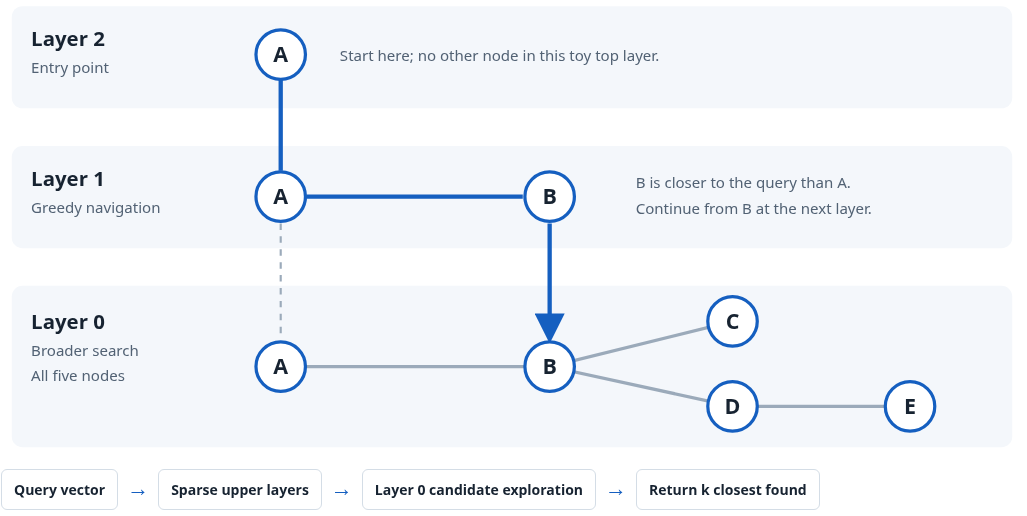

**Figure.** The same five-node hierarchy used in the search trace. The blue route goes from A at the top to B at the base. Vertical movement changes the layer, not the vector. The node positions are a diagram layout, not a plot of cosine distances. This is a static diagram; its text describes the search steps.

### Why upper layers become smaller

A new node receives a random maximum level. With $U$ uniformly distributed between zero and one, the sampling rule is [R6, R7]:

$$L=\lfloor-\ln(U)\,m_L\rfloor.$$

A common choice is $m_L=1/\ln M$. The probability that a node appears at layer $\ell$ is then:

$$P(L\geq\ell)=e^{-\ell/m_L}=M^{-\ell}.$$

Since each of the $D$ nodes has that membership probability, the expected layer population is:

$$\mathbb{E}[D_\ell]=D\,M^{-\ell}.$$

For $D=30{,}000$ and $M=16$, the expectations are:

| Layer | Membership probability | Expected nodes |
|:--|:--|--:|
| 0 | $1$ | 30,000 |
| 1 | $1/16$ | 1,875 |
| 2 | $1/256$ | 117.19 |
| 3 | $1/4096$ | 7.32 |
| 4 | $1/65536$ | 0.46 |

These are expectations, not fixed counts. An expectation of 0.46 does not mean a real graph contains part of a node. Actual heights and the highest occupied layer depend on the random assignments. The five-node diagram is hand-built to explain navigation; it is not a random sample of the 30,000-node example.

<a id="hnsw-search"></a>
### Query navigation: first a region, then alternatives

At the upper layers, start from the entry node and repeatedly move to a connected node closer to the query. When no connected improvement is available, descend at the current node. At layer 0, perform a broader best-first search instead of committing to only one greedy path [R6].

Use the following fixed query distances:

| Node | A | B | C | D | E |
|:--|--:|--:|--:|--:|--:|
| Distance to query | 0.90 | 0.60 | 0.30 | 0.50 | 0.05 |

In the diagram, layer 2 contains only A. At layer 1, B is closer than A because $0.60<0.90$. Move A → B and descend to **B in layer 0**.

```text
Layer 2: A
         ↓
Layer 1: A → B
             ↓
Layer 0:     B  → broader exploration
```

The base-layer edges are A—B, B—C, B—D, and D—E:

```text
                     C: 0.30
                    /
   A: 0.90 — B: 0.60
                    \
                     D: 0.50 — E: 0.05
```

A single greedy path from B chooses C because C is closer than D. At C, the only neighbour is B, which is farther away. The walk stops at C even though E is the global nearest node. Reaching E requires preserving the less immediately attractive alternative through D.

**The key idea:** a candidate that is not the best now can lead to a much better candidate later.

### Three collections with different jobs

The canonical layer search uses a frontier, retained candidates, and visited-node bookkeeping [R6, R7]. Here we call them $F$, $W$, and $V$:

| Collection | Meaning | What happens to it? |
|:--|:--|:--|
| $F$: frontier | Discovered candidates waiting for possible expansion | Take the closest pending node next; new useful candidates enter |
| $W$: retained candidates | Best discovered nodes currently being kept | Retain at most `efSearch`; evict the worst when necessary |
| $V$: visited set | Nodes whose query distance has already been evaluated | Prevent repeated evaluation of the same node during this layer search |

A node is **evaluated** when its distance is computed. It is **expanded** when its neighbour list is inspected. A node can be evaluated but never expanded. Here, discovering D does not imply discovering E: the search must expand D to inspect its edge to E.

In a heap-based implementation, $F$ is accessed by its nearest candidate, while $W$ must efficiently expose its farthest retained member. An evicted node can remain as a stale entry in $F$ until later removal. Consequently, `efSearch` bounds the retained set in this conceptual algorithm; it is **not** a hard cap on the visited set, total expansions, or total distance calculations.

```text
Take the closest pending node from F
                ↓
Apply the stopping test
                ↓
Inspect that node's neighbours
                ↓
For each unseen neighbour: add it to V and evaluate its distance
                ↓
If W is not full, or this neighbour improves W:
    add it to F and W
    trim the worst member if W exceeds efSearch
                ↓
Repeat; finally return the closest k members of W
```

NMSLIB has optimized search paths. This is a teaching model of the canonical procedure, not a claim that every NMSLIB configuration executes precisely these instructions [R7].

<a id="hnsw-trace"></a>
### Worked search: `efSearch = 1` versus `efSearch = 2`

Upper-layer navigation has already brought us to B. We request $k=1$. For reproducibility, inspect B's neighbours in the order A, C, D.

**Narrow search: `efSearch = 1`.** Start with $W=\{B\}$. A at 0.90 is worse than B at 0.60, so do not retain it. C at 0.30 replaces B. D at 0.50 is now worse than C, so do not retain it. Expand C, find only the already visited B, and finish.

| Action | Frontier $F$ | Retained $W$, closest first | Consequence |
|:--|:--|:--|:--|
| Start at B | B | B | One retained slot |
| Expand B; evaluate A | empty | B | A is not competitive |
| Evaluate C | C | C | C replaces B |
| Evaluate D | C | C | D is not retained |
| Expand C | empty | C | No new neighbour |
| Return top 1 | empty | C | Return C at 0.30; miss E at 0.05 |

Distances were evaluated for B, A, C, and D: **four evaluations despite `efSearch = 1`**. Only B and C were expanded. Recall@1 is zero in this constructed example.

**Broader search: `efSearch = 2`.** Initially, A is accepted because the retained list is not full. C then displaces A. D displaces B, so the two retained alternatives are C and D. C reveals nothing new, but D reveals E.

| Action | Frontier $F$ | Retained $W$, closest first | Consequence |
|:--|:--|:--|:--|
| Start at B | B | B | Two retained slots available |
| Expand B; evaluate A | A | B, A | W was not full |
| Evaluate C | C, A | C, B | Evict A from W, not immediately from F |
| Evaluate D | C, D, A | C, D | Evict B from W; retain the D alternative |
| Expand C | D, A | C, D | No new node |
| Expand D; evaluate E | E, A | E, C | E replaces D in W |
| Expand E | A | E, C | D was already visited |
| Pop A; stopping test succeeds | empty | E, C | A at 0.90 is worse than the worst retained C at 0.30 |
| Return top 1 | empty | E, C | Return E at 0.05 |

Here all five nodes were evaluated; B, C, D, and E were expanded. The requested output still contains only one node, E. Recall@1 is one.

```text
efSearch = 1:   B → C             return C

efSearch = 2:   B → C
                \
                 → D → E         return E
```

We changed the exploration breadth, not the vectors, graph, query, distance function, or output count.

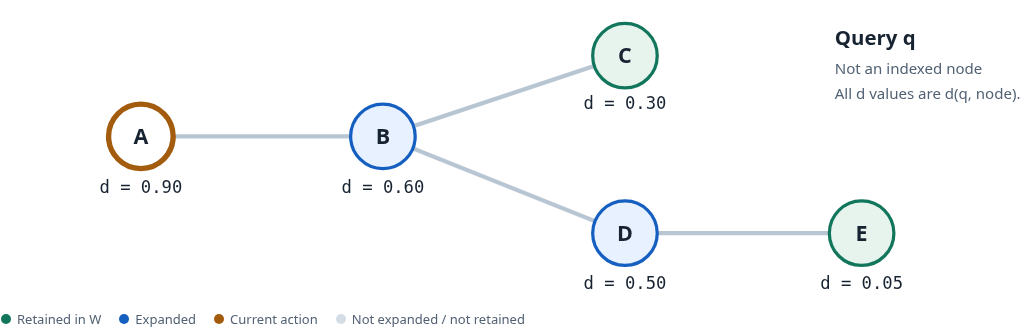

**Figure.** Final state for the broader search. C and E remain in W; with k = 1 only E is returned. B and D were expanded. A has already been evaluated but is not expanded because the stopping test rejects it. Distances are to the external query q. These marks visualize the hand trace, not a measured NMSLIB execution.

### Why the stopping rule is still approximate

Once $W$ is full, compare the closest pending candidate with the worst retained candidate. A common stopping condition is [R6]:

$$\delta(q,\mathrm{best\ pending})>\delta(q,\mathrm{worst\ retained}).$$

This says the remaining frontier is no longer competitive under the search rule. It does **not** prove that every unseen node is worse. A less promising pending node might lead to an excellent unseen node. The algorithm chooses not to inspect every route; this is where approximation enters.

`efSearch = 2` solved the example, but it is not a guarantee for other graphs or queries. Increasing the breadth often improves recall at the expense of additional work. The graph's connectivity and the embedding geometry still matter.

### Readable implementation of the teaching trace

The following demonstration is supplied in **both** editions so the search decisions can be studied independently of the main exercises. It needs only Python's standard library. Its distance dictionary is a stand-in for computing distances from real vectors. It does not construct an HNSW graph, train an embedding, or measure NMSLIB speed.

**Implementation steps.** Initialise $F$, $W$, and $V$ with B. Repeatedly pop the nearest frontier node. Stop when it is worse than the worst retained node and W is full. Otherwise expand it, evaluate unseen neighbours, admit competitive ones, and trim W. Return the closest k retained IDs. The dictionary used for W is intentionally readable rather than performance-optimized.

In [ ]:
# Provided teaching demonstration: no NMSLIB or pretrained model is needed.
# This is a single-layer SEARCH_LAYER illustration, not a full HNSW index.
import heapq
from math import isfinite

TEACHING_GRAPH = {
    "A": ["B"],
    "B": ["A", "C", "D"],  # Neighbour order is fixed for a reproducible trace.
    "C": ["B"],
    "D": ["B", "E"],
    "E": ["D"],
}
TEACHING_DISTANCES = {"A": 0.90, "B": 0.60, "C": 0.30, "D": 0.50, "E": 0.05}


def trace_hnsw_layer(graph, distance_to_query, entry="B", ef=2, k=1):
    """Trace a canonical best-first layer search using supplied query distances.

    F is a min-heap frontier; W retains up to ef best discovered nodes.
    V records evaluated nodes. A small dictionary replaces a production
    max-heap for W so that the algorithm is easier to inspect.
    """
    if not isinstance(ef, int) or not isinstance(k, int) or not 1 <= k <= ef:
        raise ValueError("Require integer ef and k with 1 <= k <= ef.")
    if entry not in graph or set(distance_to_query) != set(graph):
        raise ValueError("The entry and one distance per graph node are required.")
    if any(n not in graph for neighbours in graph.values() for n in neighbours):
        raise ValueError("Every neighbour must also be a graph node.")
    if any(not isfinite(float(d)) or float(d) < 0 for d in distance_to_query.values()):
        raise ValueError("All supplied distances must be finite and nonnegative.")

    distances = {node: float(d) for node, d in distance_to_query.items()}
    frontier = [(distances[entry], entry)]
    retained = {entry: distances[entry]}
    visited = {entry}
    expanded = []
    history = []

    def snapshot(action):
        history.append({
            "action": action,
            "F": [node for _, node in sorted(frontier)],
            "W": sorted(retained, key=lambda node: (retained[node], node)),
            "V": sorted(visited),
            "expanded": expanded.copy(),
        })

    snapshot(f"Start at {entry}")
    while frontier:
        candidate_distance, candidate = heapq.heappop(frontier)
        worst_distance = max(retained.values())
        if len(retained) >= ef and candidate_distance > worst_distance:
            snapshot(f"Stop: {candidate} is worse than the worst retained node")
            break
        expanded.append(candidate)
        snapshot(f"Expand {candidate}")
        for neighbour in graph[candidate]:
            if neighbour in visited:
                continue
            visited.add(neighbour)
            d = distances[neighbour]
            if len(retained) < ef or d < max(retained.values()):
                heapq.heappush(frontier, (d, neighbour))
                retained[neighbour] = d
                evicted = None
                if len(retained) > ef:
                    evicted = max(retained, key=lambda node: (retained[node], node))
                    del retained[evicted]
                message = f"Evaluate {neighbour}: keep"
                if evicted is not None:
                    message += f"; evict {evicted} from W"
            else:
                message = f"Evaluate {neighbour}: do not retain"
            snapshot(message)

    ordered = sorted(retained, key=lambda node: (retained[node], node))
    result = ordered[:k]
    snapshot("Return " + ", ".join(result))
    return {
        "ids": result,
        "distances": [retained[node] for node in result],
        "evaluated_count": len(visited),
        "expanded": expanded,
        "retained": ordered,
        "history": history,
    }


for teaching_ef in (1, 2):
    run = trace_hnsw_layer(TEACHING_GRAPH, TEACHING_DISTANCES, ef=teaching_ef)
    print(f"ef={teaching_ef} | returned={run['ids']} | "
          f"evaluated={run['evaluated_count']} | expanded={run['expanded']}")

narrow = trace_hnsw_layer(TEACHING_GRAPH, TEACHING_DISTANCES, ef=1)
wide = trace_hnsw_layer(TEACHING_GRAPH, TEACHING_DISTANCES, ef=2)
assert narrow["ids"] == ["C"] and narrow["evaluated_count"] == 4
assert wide["ids"] == ["E"] and wide["evaluated_count"] == 5
assert wide["expanded"] == ["B", "C", "D", "E"]
assert all(len(step["W"]) <= 2 for step in wide["history"])
print("Teaching-search checks passed.")


ef=1 | returned=['C'] | evaluated=4 | expanded=['B', 'C']
ef=2 | returned=['E'] | evaluated=5 | expanded=['B', 'C', 'D', 'E']
Teaching-search checks passed.


In [ ]:
# Display every state for ef=2. Re-run with ef=1 to compare.
# F can contain a stale candidate that has already been removed from W.
teaching_run = trace_hnsw_layer(TEACHING_GRAPH, TEACHING_DISTANCES, ef=2, k=1)
for step_number, step in enumerate(teaching_run["history"]):
    print(f"{step_number:2d}. {step['action']}")
    print(f"    F={step['F']}  W={step['W']}  V={step['V']}")


 0. Start at B
    F=['B']  W=['B']  V=['B']
 1. Expand B
    F=[]  W=['B']  V=['B']
 2. Evaluate A: keep
    F=['A']  W=['B', 'A']  V=['A', 'B']
 3. Evaluate C: keep; evict A from W
    F=['C', 'A']  W=['C', 'B']  V=['A', 'B', 'C']
 4. Evaluate D: keep; evict B from W
    F=['C', 'D', 'A']  W=['C', 'D']  V=['A', 'B', 'C', 'D']
 5. Expand C
    F=['D', 'A']  W=['C', 'D']  V=['A', 'B', 'C', 'D']
 6. Expand D
    F=['A']  W=['C', 'D']  V=['A', 'B', 'C', 'D']
 7. Evaluate E: keep; evict D from W
    F=['E', 'A']  W=['E', 'C']  V=['A', 'B', 'C', 'D', 'E']
 8. Expand E
    F=['A']  W=['E', 'C']  V=['A', 'B', 'C', 'D', 'E']
 9. Stop: A is worse than the worst retained node
    F=[]  W=['E', 'C']  V=['A', 'B', 'C', 'D', 'E']
10. Return E
    F=[]  W=['E', 'C']  V=['A', 'B', 'C', 'D', 'E']


### Try a different route difficulty

Make a copy of `TEACHING_DISTANCES` and change only D's distance from 0.50 to 0.80. Leave the graph, entry B, and $k=1$ unchanged. Predict the results for `ef=2` and `ef=3`, then use `trace_hnsw_layer` to check.

**Hint.** After C is found, consider whether D is closer than the worst retained member of W. A candidate can only reveal its neighbours when it is expanded. Do not change E's distance.

Explain in your own words why a larger retained list solved the original example but the same list size need not solve this modified example. Record the returned node, the retained set, and the number of evaluated nodes for each run.

<a id="hnsw-construction"></a>
### Construction: how the routes are created

Querying assumes useful links already exist. HNSW creates them incrementally by inserting one vector at a time [R6, R7]. During insertion, the new vector temporarily acts as a query: which existing nodes should it connect to?

```text
New stored vector z
        ↓
Sample its maximum layer Lz
        ↓
Start at the existing top-layer entry point
        ↓
Above Lz: navigate greedily toward z
        ↓
At each layer containing z:
    search for connection candidates using efConstruction
    select useful neighbours
    connect z and update neighbour lists
    prune lists that exceed their degree limits
        ↓
Continue down to layer 0
        ↓
If z is taller than the previous graph, update the top entry point
```

Suppose the existing highest layer is 3 but $L_z=1$. Layers 3 and 2 are used for navigation only. The new vector is inserted into layers 1 and 0. It is not added to the higher layers.

Connections are proposed in both directions, but subsequent pruning can remove a link from an individual adjacency list. The algorithm's neighbour lists should not be taught as a guarantee that every final edge is perfectly symmetric. The five-node teaching example uses symmetric links for clarity.

`efConstruction` controls the search effort spent discovering candidates while building these links. It is not the breadth used later for every user query. `post` selects additional NMSLIB graph postprocessing; the lab retains the source setting `post=2` and holds it fixed [R2].

### Why useful neighbours are not always the nearest M points

Several extremely close candidates may all lead into nearly the same region. A neighbour-selection heuristic tries to avoid spending the entire link budget on redundant routes. One form compares each candidate's distance to the new node with its distances to already selected neighbours [R6, R7].

**For this geometric example only, use Euclidean distance.** This change is just to make the small coordinates easy to interpret; the Jeopardy index still uses cosine distance.

Let $z=(0,0)$ be the new vector, with candidates $A=(1,0)$, $B=(1.1,0.1)$, and $C=(0,1.2)$.

```text
    C (0, 1.2)
    •

    z (0, 0)               A (1, 0)  B (1.1, 0.1)
    •                      •        •
```

The candidate distances are $d(z,A)=1$, $d(z,B)\approx1.105$, and $d(z,C)=1.2$. Selecting only the closest two would choose A and B. But $d(A,B)\approx0.141$: B is very close to an already selected A. Its link is comparatively redundant.

By contrast, $d(A,C)\approx1.562>d(z,C)=1.2$. C provides coverage in a different direction. A diversity heuristic can reject B and retain C, connecting z to A and C instead.

A simplified acceptance condition for candidate c and already selected neighbours S is:

$$d(c,s)\geq d(c,z)\quad\mathrm{for\ every}\ s\in S.$$

Tie rules, additional filling steps, and implementation variants can differ. The purpose of this example is the navigation principle: a useful graph is not merely the result of connecting every node to its M geometrically closest points.

<a id="hnsw-parameters"></a>
### Four controls, four different questions

| Control | Question it answers | When applied | Rebuild needed? |
|:--|:--|:--|:--|
| `M` | How much connectivity should the graph provide? | Construction | Yes |
| `efConstruction` | How broadly should we search while choosing links? | Construction | Yes |
| `efSearch` | How broadly should we explore available routes? | Query configuration | No |
| `k` | How many final neighbours should be returned? | Query call | No |

**M is not an exact degree for every node.** NMSLIB normally uses a maximum of M links above layer 0 and 2M in layer 0, unless separately configured [R2]. Some nodes have fewer links. Larger M uses more link storage and can improve navigation, but it also exposes more neighbours to inspect.

**efConstruction is an upfront investment.** With M fixed, a larger construction breadth spends more work looking for useful connection candidates. The intended benefit is a better graph, at a build-time cost. It does not prescribe future query effort.

**efSearch is a per-query investment.** A larger breadth preserves more alternatives on the existing graph. It generally trades additional retrieval work for improved recall. These are tendencies to evaluate, not guarantees of perfectly monotonic measurements.

**k is the output count.** With `k=10` and `efSearch=100`, the request is to search more broadly and return ten results, not 100. In this lab, query configuration explicitly uses:

$$ef_{\mathrm{effective}}=\max(ef_{\mathrm{requested}},k).$$

This is a policy implemented by the lab helper, not an assumption about every NMSLIB build. It will be logged in the experiments. For k=1000, requested values 100, 200, and 400 all become 1000; they do not represent three different query breadths.

### What is stored and where the work goes

A rough storage model is $O(Dd)$ for the vectors plus $O(DM)$ for graph links. The 30,000 by 300 float32 matrix alone takes $30{,}000\times300\times4=36{,}000{,}000$ bytes. Text, model weights, graph metadata, links, and temporary buffers are additional.

Exact scanning computes distances to D vectors. If a graph search evaluates $v=|V|$ distinct vectors, its distance work is roughly proportional to $vd$, plus navigation and queue overhead. We seek $v\ll D$, but must measure the actual speedup. Sparse upper layers do not establish an unconditional worst-case logarithmic query guarantee.

For reproducibility, hold thread counts, model, preprocessing, query set, distance, k, and corpus fixed when testing search breadth. The paired grid later in this lab varies construction and search settings together; the controlled sweep isolates query breadth.

### Why the library can use a non-metric distance

The term **non-metric** does not mean a distance is useless. It means it need not satisfy every requirement of a mathematical metric. One requirement is the triangle inequality:

$$d(a,c)\leq d(a,b)+d(b,c).$$

Cosine distance can violate it. Take unit vectors at angles 0°, 60°, and 120°. Then:

$$d(a,b)=1-\cos(60^\circ)=0.5,$$

$$d(b,c)=1-\cos(60^\circ)=0.5,$$

$$d(a,c)=1-\cos(120^\circ)=1.5.$$

Since $1.5>0.5+0.5$, the triangle inequality fails. NMSLIB nevertheless provides cosine distance as `cosinesimil`; its angular-distance space is a different choice [R3]. We keep the cosine space consistent in the exact reference and HNSW experiment.

This example explains the library's name and a property of the chosen distance. It is **not** the sole reason HNSW is approximate: finite graph search can miss neighbours even under Euclidean distance.

<a id="nmslib-lifecycle"></a>
### Map the concepts to NMSLIB calls

| Stage | API call | What changes? |
|:--|:--|:--|
| Choose method and space | `nmslib.init(method="hnsw", space="cosinesimil")` | Select HNSW and cosine distance |
| Supply stored items | `index.addDataPointBatch(X)` | Add vectors; by default row positions become IDs |
| Build the graph | `index.createIndex({...})` | Apply M, efConstruction, postprocessing, and build-thread settings |
| Set retrieval effort | `index.setQueryTimeParams({"efSearch": ef})` | Change query effort on the same graph |
| Query one vector | `index.knnQuery(q, k=k)` | Return IDs and distances for that query |
| Query several vectors | `index.knnQueryBatch(Q, k=k, num_threads=...)` | Return one `(ids, distances)` pair per query |

These are distinct stages of the NMSLIB API [R1]. A query result ID refers to the vector row used at insertion; use the matching row in `records` to retrieve the original question. Do not reorder or filter only one side of this mapping.

```text
Returned ID 42 → X[42] → records[42]["Question"]

Two-query batch requesting three neighbours:
    first query  → [42, 17, 8]
    second query → [91, 3, 26]
```

Keep the outer query structure. Flattening these lists would mix different rankings and invalidate per-query recall. Distances help interpret closeness; IDs are used in the overlap metric.

**Correction already made in the improved lab.** `space_params` configures the distance space. It is not the correct place for HNSW's M, efConstruction, and efSearch. Construction parameters belong in `createIndex`; query parameters belong in `setQueryTimeParams` [R1, R2, R7].

### Before implementation

Check that X is a nonempty two-dimensional numeric array, all entries are finite, no vector is zero, and each query has the same dimension. The lab uses contiguous float32 arrays. Zero vectors are invalid for the cosine formula. A change of embedding model requires rebuilding corpus vectors, query vectors, exact references, and indices.

The following core exercises implement these stages. The supplied trace above explains **why** search works; NMSLIB performs the actual graph construction and retrieval in the lab.

In [ ]:
def checked_matrix(data, name="vectors"):
    data = np.asarray(data, dtype=np.float32)
    if data.ndim != 2 or data.shape[0] == 0 or data.shape[1] == 0:
        raise ValueError(f"{name} must be a nonempty two-dimensional matrix.")
    if not np.isfinite(data).all():
        raise ValueError(f"{name} contains NaN or infinity.")
    if np.any(np.linalg.norm(data, axis=1) <= EPS):
        raise ValueError(f"{name} contains zero vectors.")
    return np.ascontiguousarray(data)


### Implementation C · Build the correct index

**Inputs:** a vector matrix, method name, optional prefix size, and HNSW parameters. **Output:** a ready-to-query NMSLIB index.

**Steps.** Validate and slice the matrix. Initialise the requested method with `space='cosinesimil'`. Add the matrix. For HNSW, build with `M`, `efConstruction`, `post`, and the build thread count. Then set `efSearch`. For `brute_force`, build without graph parameters.

**Hint.** The three API stages are `init` → `addDataPointBatch` → `createIndex`. Query-time configuration is a separate call. The default IDs are the added matrix's row positions [R1]. We deliberately avoid arbitrary ID remapping in this lab.


In [ ]:
def get_index(data, method="hnsw", *, cutoff=None, M=16,
              efConstruction=200, efSearch=100, post=2, build_threads=1):
    try:
        import nmslib
    except ImportError as exc:
        raise ImportError("Install nmslib in the notebook kernel's environment.") from exc
    data = checked_matrix(data)
    if cutoff is not None:
        if not isinstance(cutoff, (int, np.integer)) or not 1 <= cutoff <= len(data):
            raise ValueError("cutoff must select a nonempty prefix of the matrix.")
        data = data[:cutoff]
    if method not in {"hnsw", "brute_force"}:
        raise ValueError("Use 'hnsw' or 'brute_force' in this lab.")
    # TODO: initialise, add data, build, and configure query-time parameters.
    # Pass graph settings to createIndex, not to space_params.
    raise NotImplementedError("Implement get_index for both methods.")


### Implementation D · Query one vector and a batch

**Input:** a built index, one vector or a query matrix, and `nn` (the requested neighbour count). **Output:** IDs sorted by increasing distance. A batch returns one list per query, in input order.

**Steps for one query.** Validate a one-dimensional vector, call `knnQuery(vector, k=nn)`, unpack IDs and distances, and return IDs in distance order. **Steps for a batch.** Validate the query matrix, call `knnQueryBatch`, unpack every `(ids, distances)` pair, and create the outer list.

**Hint.** For $Q$ queries requesting $k$ neighbours, expect $Q$ lists, normally each with $k$ IDs. Keep `num_threads` explicit. The wrappers retain short result lists so evaluation can reveal and penalise missing results rather than hiding them.


In [ ]:
def find_for_vector(index, vector, nn: int) -> list:
    vector = np.asarray(vector, dtype=np.float32)
    if vector.ndim != 1 or vector.size == 0 or nn < 1:
        raise ValueError("Provide a one-dimensional vector and nn>=1.")
    vector = checked_matrix(vector[None, :], "query")[0]
    # TODO: call knnQuery, unpack both arrays, return IDs in distance order.
    raise NotImplementedError("Implement find_for_vector.")

def find_for_batch(index, batch, nn: int, num_threads=1) -> list:
    if nn < 1 or num_threads < 1:
        raise ValueError("nn and num_threads must be positive.")
    if len(batch) == 0:
        return []
    batch = checked_matrix(batch, "query batch")
    # TODO: call knnQueryBatch and extract one sorted ID list per query.
    raise NotImplementedError("Implement find_for_batch.")


In [ ]:
toy_flat = get_index(TOY_VECTORS, method="brute_force")
assert find_for_vector(toy_flat, TOY_QUERY, 2) == [0, 1]
toy_batch = find_for_batch(toy_flat, np.array([TOY_QUERY, [-1, 0]], dtype=np.float32), 2)
assert toy_batch == [[0, 1], [3, 2]]
print("NMSLIB query checks passed.")
del toy_flat


### NMSLIB results, changing effort, and saving an index

The wrappers above return ranked IDs. The underlying API also returns distances [R1]. The following is a reading example to connect the API to the helper functions; it is not another required exercise:

```python
# Assumes index has already been built, q has the right dimension,
# and 1 <= k <= the number of stored vectors.
index.setQueryTimeParams({"efSearch": max(requested_ef, k)})
ids, distances = index.knnQuery(q, k=k)

for rank, (item_id, distance) in enumerate(zip(ids, distances), start=1):
    print(rank, int(item_id), float(distance))

# Reuse the graph and change only retrieval effort.
index.setQueryTimeParams({"efSearch": max(300, k)})
ids, distances = index.knnQuery(q, k=k)
```

Smaller `cosinesimil` distances are better. The query is not inserted. The index does not replace your ID-to-question mapping. The batch function returns a separate ranking for each query; using several query threads affects batch processing, not the meaning of the outer list.

To avoid rebuilding a completed HNSW index, NMSLIB provides saving and loading [R1]. Keep the model identity, distance, data version, and ID-to-record mapping together with the saved index. Treat any companion files produced by the library as part of the saved artifact.

```python
# Optional example after you have built an index.
import nmslib

index.saveIndex("questions_hnsw.bin", save_data=True)

loaded = nmslib.init(method="hnsw", space="cosinesimil")
loaded.loadIndex("questions_hnsw.bin", load_data=True)
loaded.setQueryTimeParams({"efSearch": 100})
```

Saving the graph does not preserve your Python `records` variable or your preprocessing code. Save that information separately, and reapply the intended query settings after loading.

### Build the query bucket

In the source, `bucket` means a **collection of evaluation queries**. It is not a hash bucket, a graph layer, or a set of human relevance labels. It starts with 21 topics and appends the questions at positions `150:14000:7` together with their existing vectors.

The revised code retains that pattern. The classroom profile takes at most 100 of those sampled questions. Topic queries are embedded using the same function and cleaning. Their vectors must be finite and nonzero too.

Some sampled questions are already inside a given index. A copy of an indexed vector can retrieve itself at distance zero. This is useful as a sanity check but can make the benchmark easier, particularly at small $k$. The same sampled question can be outside the 2,000-row prefix and inside the 30,000-row prefix. Therefore we retain corpus positions and report query groups relative to the actual $D$.

For a stronger deployment evaluation, add a separate representative held-out query set. Do not call the source's in-corpus queries held-out queries.


In [ ]:
TOPICS = ["opera", "math", "geography", "films", "cats", "zebra",
          "cooking", "armory", "war", "history", "money", "books",
          "quantum physics", "snakes", "sea", "plants", "chemistry",
          "stars", "science fiction", "languages", "clothes"]

bucket, bucket_vectors, query_metadata = [], [], []
for topic in TOPICS:
    vector = embed(clean_text(topic))
    if not np.isfinite(vector).all() or np.linalg.norm(vector) <= EPS:
        print("Skipped invalid topic vector:", topic)
        continue
    bucket.append(topic)
    bucket_vectors.append(vector)
    query_metadata.append({"kind": "topic", "corpus_position": None})

sample_ids = list(range(150, min(14000, len(records)), 7))
if CFG["max_sample_queries"] is not None:
    sample_ids = sample_ids[:CFG["max_sample_queries"]]
for i in sample_ids:
    bucket.append(records[i]["Question"])
    bucket_vectors.append(vectors[i])
    query_metadata.append({"kind": "sampled_question", "corpus_position": i})

bucket_vectors = checked_matrix(np.vstack(bucket_vectors), "query bucket")
assert len(bucket) == len(bucket_vectors) == len(query_metadata)
print("Queries:", len(bucket), "| query matrix:", bucket_vectors.shape)
print("Topic queries:", sum(m["kind"] == "topic" for m in query_metadata))
print("Sampled questions:", len(sample_ids))


### Establish a trustworthy exact reference

For every dataset size $D$, build a separate brute-force index on `vectors[:D]` and query the same bucket. Results from a 30,000-row index are not the correct reference for a 2,000-row index.

The exact reference must contain at least as many unique IDs as the evaluation cutoff. We compute 1,000 exact neighbours for the main experiments. Later, the top-2,000 demonstration computes a fresh top-2,000 reference explicitly.

### Timing protocol

Use `time.perf_counter` to measure elapsed wall-clock time. Warm up the query path, repeat the same batch, and use the median. A timed batch includes wrapper validation and ID conversion; it excludes embedding, disk loading, graph construction, and plotting. Both methods use the same query batch and thread count.

$$\mathrm{QPS}=\frac{Q}{T_{\mathrm{batch}}},\qquad t_{\mathrm{amortised}}=\frac{T_{\mathrm{batch}}}{Q}.$$

The second quantity is an amortised batch time per query. With multiple threads it is **not** isolated single-query latency. Build time in this lab includes input validation, insertion, and `createIndex`; it is not embedding time.


In [ ]:
def timed_batch(index, queries, nn: int, *, repeats=3, num_threads=1):
    if repeats < 1 or len(queries) == 0:
        raise ValueError("Use a nonempty batch and at least one timed repetition.")
    find_for_batch(index, queries[:min(8, len(queries))], nn, num_threads)
    timings = []
    for _ in range(repeats):
        start = time.perf_counter()
        ids = find_for_batch(index, queries, nn, num_threads)
        timings.append(time.perf_counter() - start)
    return float(np.median(timings)), ids


ground_truth, flat_timings = {}, {}
for D in tqdm(DS, desc="Exact references"):
    start = time.perf_counter()
    flat = get_index(vectors, method="brute_force", cutoff=D)
    build_seconds = time.perf_counter() - start
    t100, _ = timed_batch(flat, bucket_vectors, K_SMALL,
                          repeats=REPEATS, num_threads=NUM_THREADS)
    t1000, exact_ids = timed_batch(flat, bucket_vectors, K_LARGE,
                                  repeats=REPEATS, num_threads=NUM_THREADS)
    if any(len(set(ids)) < K_LARGE for ids in exact_ids):
        raise RuntimeError("The exact reference is too short for recall@1000.")
    ground_truth[D] = exact_ids
    flat_timings[D] = {"build_s": build_seconds, "search100_s": t100,
                       "search1000_s": t1000}
    del flat
    gc.collect()
print("Reference shapes:", {D: (len(ids), len(ids[0])) for D, ids in ground_truth.items()})


### Recall measures agreement with exact neighbours

Let $A_N(q)$ be the first $N$ returned IDs and $G_N(q)$ the first $N$ exact IDs. The source lab's metric is set overlap:

$$\mathrm{Recall@}N(q)=\frac{|A_N(q)\cap G_N(q)|}{N}.$$

For exact IDs `[4, 1, 7, 2, 9]` and approximate IDs `[4, 7, 8, 2, 6]`, the common IDs are `{4, 7, 2}`. Recall@5 is $3/5=0.6$. A permutation of the same five exact IDs gives recall one: this metric checks membership, not the ordering inside the cutoff.

An approximate list may be shorter than $N$; missing results count as misses. The exact list must not be shorter than $N$. Do not fix a deficient exact reference by silently dividing by its shorter length—that changes the evaluation question.

If there are $Q$ queries, report the arithmetic mean:

$$\overline{R@N}=\frac{1}{Q}\sum_{i=1}^{Q}R@N(q_i).$$

This is neighbour recall, not ordinary relevance recall against a human-judged set. When every list has length $N$ and the target set is defined as the $N$ exact neighbours, overlap-based precision and recall have the same numerical denominator. That does not make the general IR metrics identical.

**Tie caveat.** Multiple IDs can have equal distance, especially duplicate questions. Two exact top-$N$ choices can differ at a tied boundary. The ordinary set-overlap score can then be below one even when all returned distances are equally valid. Interpret small gaps with that caveat, or use a clearly specified tie-aware rule in a separate extension.


### Implementation E · Recall at one cutoff

**Inputs:** distance-sorted result IDs, distance-sorted exact IDs, and $N$. **Output:** a number between zero and one.

**Steps.** Require positive $N$. Take the exact top $N$ and verify it has $N$ unique IDs. Take the approximate top $N$. Reject duplicate returned IDs because a nearest-neighbour list should contain unique IDs. Count the intersection and divide by $N$.

**Hint.** Python sets give intersection membership, but slice before converting to sets. Slicing after converting would destroy the meaning of “top”. An empty approximate list is valid and has recall zero.


In [ ]:
def recall_at_n(sorted_result: list, sorted_ground_truth: list, N: int) -> float:
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N must be a positive integer.")
    exact = list(sorted_ground_truth[:N])
    if len(exact) != N or len(set(exact)) != N:
        raise ValueError("Need N unique exact reference IDs; compute a deeper reference.")
    approximate = list(sorted_result[:N])
    if len(set(approximate)) != len(approximate):
        raise ValueError("Returned neighbour IDs must be unique.")
    # TODO: compute the size of the intersection and divide by N.
    raise NotImplementedError("Implement recall_at_n.")


In [ ]:
assert recall_at_n([4, 7, 8, 2, 6], [4, 1, 7, 2, 9], 5) == 0.6
assert recall_at_n([9, 2, 7, 1, 4], [4, 1, 7, 2, 9], 5) == 1.0
assert recall_at_n([], [4, 1, 7, 2, 9], 5) == 0.0
assert recall_at_n([4, 1], [4, 1, 7, 2, 9], 5) == 0.4
try:
    recall_at_n([1, 2, 3], [1, 2], 3)
except ValueError:
    print("Short exact references are correctly rejected.")
else:
    raise AssertionError("An incomplete reference must not be scored.")

# Reproduce the arithmetic check from the source without needing the dataset.
b = list(range(1000))
print(recall_at_n(b, b, 700), recall_at_n(b[:500], b, 700),
      recall_at_n(b[:350], b, 700), recall_at_n([], b, 700))


**Discuss.** Explain why the final line gives approximately `1.0, 0.714286, 0.5, 0.0`. Why would every reference list of 1,000 unique IDs give the same four numbers when sliced in this way? What does this check validate, and what does it not validate?


### Implementation F · Mean recall across the bucket

**Inputs:** one result list and one exact list for each query, plus a common cutoff. **Output:** mean recall across queries.

**Steps.** Check that the outer lists have equal, nonzero length. Evaluate corresponding query pairs. Sum the scores and divide by the number of queries actually scored.

**Hint.** Use `zip` and `np.mean`. Never divide by the length of a stale variable from an earlier loop. Equal query counts are not enough: the query order must also match.


In [ ]:
def mean_recall(results: list, references: list, N: int) -> float:
    if len(results) == 0 or len(results) != len(references):
        raise ValueError("Need equal, nonzero numbers of query results and references.")
    # TODO: score each aligned pair and return their arithmetic mean.
    raise NotImplementedError("Implement mean_recall.")


In [ ]:
assert np.isclose(mean_recall([[0, 2], [1, 3]], [[0, 1], [1, 3]], 2), 0.75)
print("Mean-recall check passed.")


## 2 · Test HNSW and inspect what it retrieves

Start with one HNSW graph, not the full grid. Inspect actual questions as well as scores. A low neighbour recall suggests a search approximation issue; poor meaning despite high neighbour recall suggests a representation or task-definition issue.

### Search breadth and requested results

`efSearch` is a search-list breadth control, not the number of graph layers, not the number of returned neighbours, and not an exact count of distance calculations. To avoid an undersized retained candidate list in this exercise, use a deliberate policy:

$$ef_{\mathrm{effective}}=\max(ef_{\mathrm{requested}},k).$$

This is an **explicit experimental choice**, not a claim that every NMSLIB build automatically applies that rule. The helper returns the effective value so it can be logged. At $k=1000$, requested values 100, 200, and 400 all become 1000; they cannot establish the isolated effect of three different query breadths. We will fix that with a separate controlled sweep in Section 3.

### The top-2,000 correction

The source asks for recall@2000 after computing only 1,000 reference IDs. Its score can be at most $1000/2000=0.5$, even if every available reference ID is returned. That result is not a valid recall@2000 measurement. Here the one-query demonstration computes a fresh exact reference at the largest tested cutoff.


In [ ]:
def configure_search(index, requested_ef: int, k: int) -> int:
    if requested_ef < 1 or k < 1:
        raise ValueError("Search breadth and k must be positive.")
    effective = max(int(requested_ef), int(k))
    index.setQueryTimeParams({"efSearch": effective})
    return effective

D_DEMO = max(DS)
hnsw = get_index(vectors, cutoff=D_DEMO, M=16, efConstruction=200,
                 efSearch=100, post=POST, build_threads=BUILD_THREADS)
query_id = bucket.index("zebra") if "zebra" in bucket else 0
query = bucket_vectors[query_id]
ks = [k for k in [100, 1000, 2000] if k <= D_DEMO]
flat_demo = get_index(vectors, method="brute_force", cutoff=D_DEMO)
reference_demo = find_for_vector(flat_demo, query, max(ks))
demo_rows = []
for k in ks:
    effective = configure_search(hnsw, 100, k)
    ids = find_for_vector(hnsw, query, k)
    demo_rows.append({"requested_k": k, "efSearch_effective": effective,
                      "returned": len(ids), "recall": recall_at_n(ids, reference_demo, k)})
print("Query:", bucket[query_id])
display(pd.DataFrame(demo_rows))
del flat_demo


In [ ]:
def show_results(index, query_text: str, rows: list, k=5):
    if not 1 <= k <= len(rows):
        raise ValueError("k must not exceed the indexed corpus size.")
    query_vector = embed(clean_text(query_text))
    checked_matrix(query_vector[None, :], "query")
    configure_search(index, 200, k)
    ids, distances = index.knnQuery(query_vector, k=k)
    order = np.argsort(distances, kind="stable")
    return pd.DataFrame([
        {"rank": rank + 1, "id": int(ids[j]), "distance": float(distances[j]),
         "question": rows[int(ids[j])]["Question"],
         "answer": rows[int(ids[j])].get("Answer", "")}
        for rank, j in enumerate(order)
    ])

display(show_results(hnsw, "quantum physics", records[:D_DEMO], k=5))


**Discuss.** Does recall necessarily decrease when the cutoff grows? Are the returned neighbours semantically convincing? What information would you need to distinguish a bad embedding from a poor approximate search?

This demonstration changes both the requested cutoff and the effective search breadth. It is useful for exercising the API, but it is not a controlled test of the effect of only one variable.


## 3 · Assess construction, retrieval, and recall

### Understand the three recall columns first

Write $A^{(k)}(q)$ for the ranked list obtained when requesting $k$ neighbours.

$$R_{100}=\frac{|A^{(100)}_{:100}\cap G_{100}|}{100},\qquad
R_{1000}=\frac{|A^{(1000)}_{:1000}\cap G_{1000}|}{1000}.$$

The source's third metric, written `recall@100*`, is:

$$R_{100\mid1000}=\frac{|A^{(1000)}_{:100}\cap G_{100}|}{100}.$$

It asks whether the first 100 items of a 1,000-result search recover the exact top 100. It is **not** the overlap between all 1,000 candidates and the exact top 100. That latter coverage metric would be:

$$C_{100\mid1000}=\frac{|A^{(1000)}_{:1000}\cap G_{100}|}{100}.$$

We retain the original top-100-prefix definition and name it `recall100_from1000` to remove the ambiguity. If a larger request explores more useful candidates, its top-100 prefix may improve. If the same search candidates are considered, the top-100 prefixes may match. Equality is not a universal law.

### A · Source-style paired grid, with visible search policy

The source varies `M`, $D$, and one `ef` used for both construction and search. We keep that paired experiment, but log **effective** query breadth after the minimum-$k$ policy. This experiment describes combined settings; it does not isolate construction breadth from query breadth.

For each combination: build an HNSW graph → time top-100 queries → time top-1000 queries → compare against `ground_truth[D]` → average over the actual query count → save all settings and measurements.

$$\mathrm{Speedup}_k=\frac{T_{\mathrm{exact},k}}{T_{\mathrm{HNSW},k}}.$$

A value above one means HNSW is faster for that measured batch. A value below one means the exact baseline is faster. A graph index is not guaranteed to win on a small collection or when $k$ is a large fraction of $D$.


### Implementation G · Evaluate one parameter configuration

**Inputs:** vector matrix, query matrix, matching exact references, exact timings, and the current `M`, `D`, and paired `ef`. **Output:** one dictionary with all settings and observations.

**Steps.** Time a new HNSW build. Configure and time top-100 retrieval. Configure and time top-1000 retrieval. Compute the three mean recall values. Add effective breadths, result-length diagnostics, QPS, and speedups. Release the graph after collecting results.

**Hint.** Build once per configuration. Query twice with the documented breadth policy. Use `references[D]`; do not compare against a different corpus. `len(queries)` is the averaging population. The return structure is supplied so results from different students have consistent columns.


In [ ]:
def evaluate_setting(data, queries, references, exact_times, M, D, ef,
                     *, repeats=3, num_threads=1, build_threads=1, post=2):
    if not K_LARGE <= D <= len(data):
        raise ValueError("D must fit the corpus and support the large-k query.")
    # Remove this line when all TODO expressions below have been completed.
    raise NotImplementedError("Complete the four stages of evaluate_setting.")

    # Stage 1: build the graph using this setting and measure its elapsed time.
    start = time.perf_counter()
    index = ...  # TODO: call get_index with D, M, ef, post, and build_threads.
    build_s = time.perf_counter() - start

    # Stage 2: configure and time the smaller result request.
    ef100 = configure_search(index, ef, K_SMALL)
    t100, ids100 = ...  # TODO: call timed_batch with K_SMALL and the timing settings.

    # Stage 3: configure and time the larger result request.
    ef1000 = configure_search(index, ef, K_LARGE)
    t1000, ids1000 = ...  # TODO: call timed_batch with K_LARGE.

    # Stage 4: use your mean_recall function with the matching reference.
    r100 = ...          # TODO: first 100 IDs of the 100-result request.
    r1000 = ...         # TODO: first 1000 IDs of the 1000-result request.
    r100_from1000 = ... # TODO: first 100 IDs of the 1000-result request.

    row = {
        "M": M, "D": D, "efConstruction": ef, "efSearch_requested": ef,
        "efSearch100_effective": ef100, "efSearch1000_effective": ef1000,
        "post": post, "queries": len(queries), "num_threads": num_threads,
        "build_threads": build_threads, "repeats": repeats,
        "build_s": build_s, "search100_s": t100, "search1000_s": t1000,
        "recall100": r100, "recall1000": r1000,
        "recall100_from1000": r100_from1000,
        "min_returned100": min(map(len, ids100)),
        "min_returned1000": min(map(len, ids1000)),
        "qps100": len(queries) / t100, "qps1000": len(queries) / t1000,
        "speedup100": exact_times[D]["search100_s"] / t100,
        "speedup1000": exact_times[D]["search1000_s"] / t1000,
    }
    del index
    gc.collect()
    return row


In [ ]:
combinations = list(product(MS, DS, EFS))
print("Paired configurations:", len(combinations))
result_rows = []
for M, D, ef in tqdm(combinations, desc="Paired grid"):
    result_rows.append(evaluate_setting(
        vectors, bucket_vectors, ground_truth, flat_timings, M, D, ef,
        repeats=REPEATS, num_threads=NUM_THREADS,
        build_threads=BUILD_THREADS, post=POST))
    # Save after each completed setting so interruption does not discard all results.
    pd.DataFrame(result_rows).to_csv(RESULTS_DIR / "paired_grid.csv", index=False)

df = pd.DataFrame(result_rows)
for column in ["recall100", "recall1000", "recall100_from1000"]:
    assert df[column].between(0, 1).all()
display(df)


### B · Isolate query breadth without rebuilding

Fix $D$, `M`, `efConstruction`, `post`, the queries, and $k=100$. Change only `efSearch` on one graph. This added experiment distinguishes query-time effort from construction quality.

The settings 100, 200, 400, 1,000, and 2,000 are all at least $k$. The query batch, reference IDs, and graph remain fixed. Timing is still noisy, and one graph is not a multi-build statistical study. A more rigorous extension repeats the entire build and reports variability.

### C · Inspect query-group recall

Report topic queries separately from sampled questions. Within a corpus prefix, classify a sampled question as `inside_this_index` or `outside_this_index`. An ID-level held-out check does not rule out duplicate text elsewhere in the index, so these labels are not a guarantee against duplicate leakage.


In [ ]:
D_FIXED = max(DS)
fixed_index = get_index(vectors, cutoff=D_FIXED, M=16, efConstruction=200,
                        efSearch=100, post=POST, build_threads=BUILD_THREADS)
search_rows = []
for ef_search in [100, 200, 400, 1000, 2000]:
    effective = configure_search(fixed_index, ef_search, K_SMALL)
    seconds, ids = timed_batch(fixed_index, bucket_vectors, K_SMALL,
                               repeats=REPEATS, num_threads=NUM_THREADS)
    search_rows.append({"D": D_FIXED, "M": 16, "efConstruction": 200,
                        "efSearch": effective, "k": K_SMALL,
                        "search_s": seconds, "qps": len(bucket_vectors) / seconds,
                        "recall": mean_recall(ids, ground_truth[D_FIXED], K_SMALL)})
search_df = pd.DataFrame(search_rows)
search_df.to_csv(RESULTS_DIR / "search_breadth_sweep.csv", index=False)
display(search_df)

configure_search(fixed_index, 400, K_SMALL)
group_ids = find_for_batch(fixed_index, bucket_vectors, K_SMALL, NUM_THREADS)
group_rows = []
for i, meta in enumerate(query_metadata):
    if meta["kind"] == "topic":
        group = "topic"
    elif meta["corpus_position"] < D_FIXED:
        group = "inside_this_index"
    else:
        group = "outside_this_index"
    group_rows.append({"group": group,
                       "recall100": recall_at_n(group_ids[i], ground_truth[D_FIXED][i], K_SMALL)})
group_df = pd.DataFrame(group_rows).groupby("group")["recall100"].agg(["count", "mean"])
display(group_df)
group_df.to_csv(RESULTS_DIR / "query_groups.csv")
del fixed_index


### Optional controlled construction experiment

To isolate `efConstruction`, fix $D$, `M`, `post`, and query breadth, rebuild once for each construction value, and compare build time and recall at the same $k$. To isolate `M`, likewise keep construction breadth and query breadth fixed. The source-style grid already contains the ingredients, but changing two controls together is not a causal test of either one alone.

For any claimed improvement, describe what was held fixed. Do not write “higher `M` is always faster” or “HNSW must beat brute force.” Denser graphs cost more link storage and can cost more work per expansion, but can also make navigation easier. The observed trade-off depends on data and the recall target.


## Display results and explain the trade-offs

Each figure should answer one question. Hold the other parameters fixed, label axes with units, and sort the horizontal variable before drawing lines. The first figure below follows the source's dataset-size comparison at a fixed paired `ef`. The second and third use the controlled query-breadth experiment.

### Plotting steps

Choose the question → filter the relevant settings → sort the x-axis variable → draw a separate figure → label the axes and fixed parameters → interpret both quality and cost.

No old benchmark outputs are copied into these notebooks. Your table and plots must come from your corrected run. Save numeric results as CSV so plotting can be repeated in a separate kernel when necessary; this is a workflow option, not a claim that plotting is generally incompatible with NMSLIB.


In [ ]:
import matplotlib.pyplot as plt

fixed_ef = EFS[0]
for metric, ylabel in [
    ("build_s", "Build time (seconds)"),
    ("search100_s", "Median batch search time, k=100 (seconds)"),
    ("search1000_s", "Median batch search time, k=1000 (seconds)"),
    ("recall100", "Mean recall@100"),
    ("recall1000", "Mean recall@1000"),
    ("recall100_from1000", "Mean recall@100 from a 1000-result search"),
]:
    fig, ax = plt.subplots(figsize=(7.5, 4.3))
    for M in MS:
        part = df[(df["M"] == M) & (df["efConstruction"] == fixed_ef)].sort_values("D")
        ax.plot(part["D"], part[metric], marker="o", label=f"M={M}")
    ax.set_xlabel("Indexed questions D")
    ax.set_ylabel(ylabel)
    ax.set_title(f"Paired grid; efConstruction={fixed_ef}; documented search policy")
    if metric.startswith("recall"):
        ax.set_ylim(0, 1.02)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{metric}_by_D.png", dpi=140)
    plt.show()
    plt.close(fig)

part = search_df.sort_values("efSearch")
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(part["efSearch"], part["recall"], marker="o")
ax.set_xlabel("efSearch (fixed graph, k=100)")
ax.set_ylabel("Mean recall@100")
ax.set_ylim(0, 1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.scatter(part["search_s"], part["recall"])
for row in part.itertuples():
    ax.annotate(str(row.efSearch), (row.search_s, row.recall), xytext=(4, 4),
                textcoords="offset points")
ax.set_xlabel("Median batch search time (seconds)")
ax.set_ylabel("Mean recall@100")
ax.set_title("Quality–time trade-off; labels are efSearch")
ax.set_ylim(0, 1.02)
fig.tight_layout()
plt.show()
plt.close(fig)


### Reading the measurements through the graph mechanism

Connect each experimental claim to a mechanism. Increasing `efConstruction` changes how connections are selected during rebuilding. Increasing `M` changes connectivity and storage. Increasing `efSearch` changes exploration on a fixed graph. Increasing `k` changes the output depth and may also change the effective search breadth under this lab's policy.

Recall compares returned IDs with the exact reference for the **same** indexed subset and query. It does not assess the truth of an answer or human semantic relevance. A missing approximate result is a miss; a missing reference result makes the intended cutoff invalid. Inspect both retrieved text and neighbour recall.

To isolate query effort, reuse one graph and keep the query vectors, k, thread count, and distance fixed. Record requested and effective breadth separately. Measure the time; do not infer a speedup from the algorithm name. The teaching graph above illustrates decisions but supplies no evidence about Jeopardy timings.

### What to write after inspecting your results

Explain how build time and retrieval time changed as $D$ increased. Compare `M` values only at matched settings. Use the fixed-graph sweep to explain the effect of `efSearch`. Compare the two top-100 metrics and describe whether search breadth also changed. Report any short result lists, ties, invalid embeddings, or unexpectedly invariant results.

A defensible conclusion has the form: “For this corpus, query mix, machine, and thread count, configuration A achieved mean neighbour recall R with median batch time T. Configuration B improved recall by this amount at this additional cost.” It does not claim a universal optimum.

A configuration is **dominated** when another configuration is no worse in both quality and time and strictly better in at least one. The nondominated configurations form a useful quality–cost frontier. Choose among them using a stated requirement, such as minimum acceptable recall, rather than choosing the largest parameters automatically.


In [ ]:
def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return "not installed"

manifest = {
    "mode": MODE, "profile": CFG, "actual_dataset_sizes": DS,
    "model": MODEL_ID, "embedding_fingerprint": EMBEDDING_FINGERPRINT,
    "dimension": int(vectors.shape[1]), "queries": len(bucket),
    "num_threads": NUM_THREADS, "build_threads": BUILD_THREADS,
    "repeats": REPEATS, "post": POST, "python": sys.version,
    "platform": platform.platform(), "processor": platform.processor(),
    "versions": {name: installed_version(name) for name in
                 ["numpy", "pandas", "spacy", "fasttext", "nmslib", "matplotlib"]},
    "timing_scope": "index query wrapper; excludes embedding and disk I/O",
    "search_policy": "effective efSearch = max(requested efSearch, k)",
    "query_policy": "source topics plus sampled corpus questions; self matches retained",
}
(RESULTS_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved results and experiment metadata in:", RESULTS_DIR.resolve())
# To plot later in another kernel:
# df = pd.read_csv(RESULTS_DIR / "paired_grid.csv")
# search_df = pd.read_csv(RESULTS_DIR / "search_breadth_sweep.csv")


## HNSW study checkpoint

Use the drawings and trace tables to answer these without running the large benchmark. The original lab's revision guide follows this checkpoint.

1. A vector has maximum level 2. Which layers contain it, and what changes when search descends at that node?
2. In the original five-node example with efSearch=1, why is D evaluated but E not discovered?
3. What do F, W, and V contain? Which one is bounded by the breadth in the canonical teaching algorithm?
4. Why can a node disappear from W but remain in F? How does that occur for A in the efSearch=2 trace?
5. What must change when M changes? What must change when only efSearch changes?
6. Why might a construction heuristic choose A and C rather than the two closest candidates A and B?
7. Explain why cosine distance is not necessarily a metric. Does a metric distance make HNSW exact?
8. How could neighbour recall be one while the displayed questions remain unhelpful?
9. What must be saved in addition to the binary index to recover the correct text and reproduce the experiment?
10. Predict the modified-D experiment before reading its trace: with D at 0.80, which breadth retains the route to E?

**Study synthesis**

```text
REPRESENTATION: What does similarity mean?
    embedding + distance
             ↓
CONSTRUCTION: Which routes should exist?
    random hierarchy + useful connections
    M + efConstruction
             ↓
QUERYING: How many alternatives should be explored?
    greedy upper layers + broader base-layer search
    efSearch + requested k
             ↓
EVALUATION: What was gained and what was missed?
    exact-neighbour recall + measured query/build costs
```

A route through a non-best candidate can be valuable. An evaluated node need not be expanded. A large retained list does not guarantee a relevant answer. These distinctions connect the visual walkthrough to the experiment.

## Revision guide

### Definitions to be able to explain

An **embedding** is a numerical representation of text. **Cosine distance** is one minus normalised dot-product similarity. **Exact k-NN** returns the nearest $k$ indexed vectors under a specified distance. **Approximate k-NN** seeks a useful approximation more efficiently. **HNSW** organises vectors into nested proximity graphs. **Neighbour recall** measures overlap with exact neighbours, not agreement with human relevance labels.

### Equations to reconstruct, not just memorise

$$s(q,x)=\frac{q^Tx}{\|q\|_2\|x\|_2},\qquad \delta(q,x)=1-s(q,x).$$

$$R@N=\frac{|A_N\cap G_N|}{N},\qquad \overline{R@N}=\frac{1}{Q}\sum_{i=1}^{Q}R@N(q_i).$$

$$\mathrm{QPS}=Q/T_{\mathrm{batch}},\qquad \mathrm{Speedup}=T_{\mathrm{exact}}/T_{\mathrm{ANN}}.$$

For every formula, explain what each set or variable means, the assumptions required, and whether a larger value is better. For distance, smaller is better. For recall and QPS, larger is better. For elapsed time, smaller is better.

### Self-check questions

1. Why must query and corpus vectors use the same model and preprocessing?
2. Why can two different texts have distance zero?
3. Which HNSW settings require rebuilding, and which can change on a fixed graph?
4. What is the difference between `k`, `N`, `M`, and `efSearch`?
5. Can recall@1000 be valid with only 100 exact neighbours?
6. Does a reversed exact top-10 list still have neighbour recall@10 equal to one?
7. Why does testing with indexed questions create a different query population from unseen user queries?
8. Why is `recall100_from1000` different from finding the exact top 100 anywhere in 1,000 candidates?
9. Can a graph have excellent neighbour recall but poor semantic retrieval?
10. What must be held fixed to test only the effect of `efSearch`?

### Troubleshooting by symptom

| Symptom | First checks |
|:--|:--|
| Every topic returns the same results | Check that `embed` uses its argument; compare two query vectors |
| Cosine scores contain NaN | Check zero vectors and nonfinite values before indexing |
| Displayed questions do not match distances | Check record/vector ID alignment after filtering |
| Every parameter setting looks identical | Check API parameter placement and actual effective breadth |
| Recall at a large cutoff is unexpectedly tiny | Check reference depth, returned count, correct corpus, and query order |
| Search seems faster only in a multithreaded run | Match thread counts; distinguish batch throughput from latency |
| Cached vectors give implausible results | Check model identity, text order, cleaning, and cache fingerprint |
| NMSLIB cannot import | Check the kernel environment and platform-specific installation; do not substitute fake results |

### Source fidelity and explicit changes

The dataset choice, embedding backends, cosine space, exact baseline, HNSW method, query bucket design, recall arithmetic, three reported recall variants, parameter grid, and plotting objective come from the supplied notebook.

The expanded mathematical explanations, numerical example, cleaning, validation, cache identity, model-dependent dimensions, smaller classroom profile, guarded recall, timing repetitions, effective-breadth logging, controlled query sweep, and query-group reporting are additions. The spaCy argument bug, HNSW parameter placement, insufficient top-2,000 reference, and stale averaging denominator are explicit corrections. The paired grid's dependence between construction and query parameters is retained and explained rather than hidden.

The expanded HNSW walkthrough, static embedded diagrams, trace tables, standard-library search simulator, construction example, and checkpoint are additional teaching material drawn from the companion explanation. The five-node graph and distances are illustrative, not extracted from the corpus. This revision preserves the previous implementation cells and their corrections.

The source's saved performance table is not reused. No performance results are claimed until the revised experiment is run.

## References

The supplied source is **08 - Indexing with graphs solution.ipynb.txt**. The resources below support the added background and implementation corrections; they are not replacements for the lab's scope.

**[R1]** NMSLIB Python API: `init`, `addDataPointBatch`, `createIndex`, query methods, and `setQueryTimeParams`. https://nmslib.github.io/nmslib/api.html

**[R2]** NMSLIB methods and parameters. https://github.com/nmslib/nmslib/blob/master/manual/methods.md

**[R3]** NMSLIB spaces and distances. https://github.com/nmslib/nmslib/blob/master/manual/spaces.md

**[R4]** spaCy `Doc.vector`: default average of token vectors. https://spacy.io/api/doc#vector

**[R5]** spaCy `Language.make_doc` and pipeline API. https://spacy.io/api/language#make_doc

**[R6]** Malkov and Yashunin, *Efficient and robust approximate nearest neighbor search using Hierarchical Navigable Small World graphs*. https://arxiv.org/abs/1603.09320

**[R7]** NMSLIB HNSW implementation, construction and query behaviour. https://github.com/nmslib/nmslib/blob/master/similarity_search/src/method/hnsw.cc

**[R8]** Source lab's Jeopardy archive. https://github.com/hsu-ai-course/hsu.ai/blob/master/code/datasets/nlp/JEOPARDY_CSV.zip

**[R9]** fastText Python module. https://fasttext.cc/docs/en/python-module.html

The references are retained from the preceding lab edition and the companion explanation. The present revision integrates that explanation and the existing visuals; it does not claim a new empirical benchmark or a new platform-installation check. Platform installation still needs to be verified in the environment where the class will run.
